In [1]:
import numpy as np
import plotly.graph_objects as go

# Definimos el horizonte de tiempo (ej. los últimos 50 pasos)
pasos_tiempo = np.arange(0, 50)
betas = [0.5, 0.9, 0.98] # Diferentes niveles de memoria

fig_ewma = go.Figure()

for beta in betas:
    # El peso exacto asignado a una observación de hace 't' pasos es (1-beta) * beta^t
    pesos = (1 - beta) * (beta ** pasos_tiempo)
    
    fig_ewma.add_trace(go.Scatter(
        x=pasos_tiempo, 
        y=pesos, 
        mode='lines+markers', 
        name=f'β = {beta} (Memoria ~{int(1/(1-beta))} pasos)'
    ))

fig_ewma.update_layout(
    title="Geometría del EWMA: Peso de los gradientes históricos",
    xaxis_title="Pasos en el tiempo (0 = Actual, 40 = Hace 40 iteraciones)",
    yaxis_title="Peso relativo en el cálculo",
    template="plotly_dark", # Ideal para presentaciones o VS Code oscuro
    hovermode="x unified"
)

fig_ewma.show()

In [2]:
import numpy as np
import plotly.graph_objects as go

# 1. Definir la topología (El barranco) y su gradiente
def f(x, y): 
    return x**2 + 20*y**2

def grad_f(x, y): 
    return np.array([2*x, 40*y]) # El gradiente en Y es 20 veces más fuerte

# 2. Implementación de los Optimizadores
def optimizar_gd(inicio, lr, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    for _ in range(pasos):
        pos = pos - lr * grad_f(*pos)
        ruta.append(pos.copy())
    return np.array(ruta)

def optimizar_momentum(inicio, lr, beta, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    v = np.zeros(2) # Vector de velocidad inicializado en 0
    for _ in range(pasos):
        grad = grad_f(*pos)
        v = beta * v + (1 - beta) * grad # EWMA del gradiente
        pos = pos - lr * v
        ruta.append(pos.copy())
    return np.array(ruta)

def optimizar_rmsprop(inicio, lr, beta, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    s = np.zeros(2) # Memoria de gradientes al cuadrado
    epsilon = 1e-8
    for _ in range(pasos):
        grad = grad_f(*pos)
        s = beta * s + (1 - beta) * (grad**2) # EWMA de la magnitud
        # Ajuste adaptativo: pasos grandes donde 's' es pequeño, y viceversa
        pos = pos - lr * (grad / (np.sqrt(s) + epsilon))
        ruta.append(pos.copy())
    return np.array(ruta)

# 3. Simulación
punto_inicio = [-8.0, 3.0] # Empezamos lejos y alto en la pared del barranco
pasos = 50

ruta_gd = optimizar_gd(punto_inicio, lr=0.04, pasos=pasos)
ruta_mom = optimizar_momentum(punto_inicio, lr=0.4, beta=0.9, pasos=pasos) # LR más alto compensado por momentum
ruta_rms = optimizar_rmsprop(punto_inicio, lr=0.5, beta=0.9, pasos=pasos)

# 4. Construcción del mapa de contorno interactivo
x_grid = np.linspace(-10, 10, 100)
y_grid = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = f(X, Y)

fig_espacio = go.Figure(data=[
    go.Contour(
        x=x_grid, y=y_grid, z=Z, 
        colorscale='Viridis', 
        opacity=0.6,
        contours=dict(coloring='lines', showlabels=True)
    )
])

# Agregar las trayectorias geométricas
fig_espacio.add_trace(go.Scatter(x=ruta_gd[:,0], y=ruta_gd[:,1], mode='lines+markers', name='GD Estándar (Zigzag)'))
fig_espacio.add_trace(go.Scatter(x=ruta_mom[:,0], y=ruta_mom[:,1], mode='lines+markers', name='GD + Momentum (Inercia)'))
fig_espacio.add_trace(go.Scatter(x=ruta_rms[:,0], y=ruta_rms[:,1], mode='lines+markers', name='RMSprop (Adaptativo)'))

# Marcador para el mínimo global
fig_espacio.add_trace(go.Scatter(x=[0], y=[0], mode='markers', marker=dict(color='red', size=12, symbol='star'), name='Mínimo Global'))

fig_espacio.update_layout(
    title="Análisis Geométrico de Convergencia en el Espacio de Fase",
    xaxis_title="Dimensión X (Pendiente Suave)",
    yaxis_title="Dimensión Y (Pendiente Abrupta)",
    template="plotly_dark",
    width=900,
    height=600
)

fig_espacio.show()

Generando el archivo evolucion_optimizadores.gif... Por favor espera.
¡Video/GIF generado con éxito!


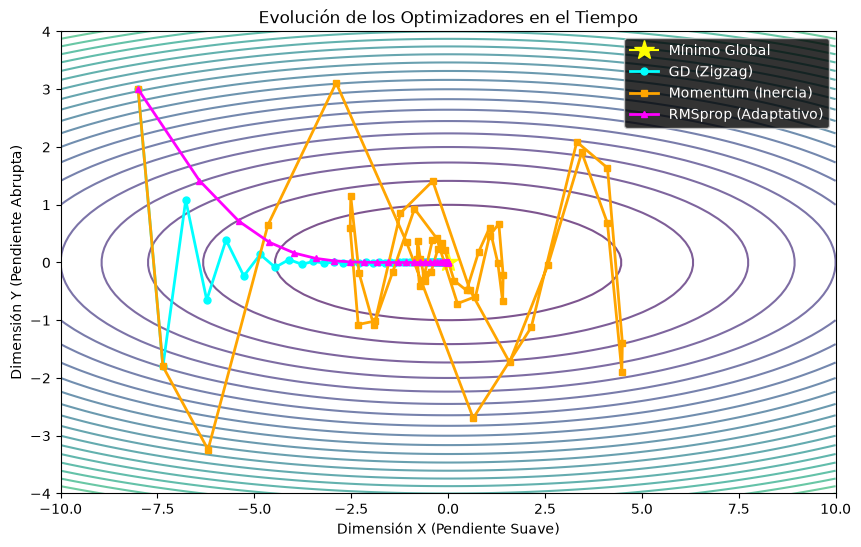

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# 1. Definir la topología y el gradiente (El barranco)
def f(x, y): 
    return x**2 + 20*y**2

def grad_f(x, y): 
    return np.array([2*x, 40*y])

# 2. Implementación de los Optimizadores
def optimizar_gd(inicio, lr, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    for _ in range(pasos):
        pos = pos - lr * grad_f(*pos)
        ruta.append(pos.copy())
    return np.array(ruta)

def optimizar_momentum(inicio, lr, beta, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    v = np.zeros(2)
    for _ in range(pasos):
        grad = grad_f(*pos)
        v = beta * v + (1 - beta) * grad
        pos = pos - lr * v
        ruta.append(pos.copy())
    return np.array(ruta)

def optimizar_rmsprop(inicio, lr, beta, pasos):
    ruta = [inicio]
    pos = np.array(inicio, dtype=float)
    s = np.zeros(2)
    epsilon = 1e-8
    for _ in range(pasos):
        grad = grad_f(*pos)
        s = beta * s + (1 - beta) * (grad**2)
        pos = pos - lr * (grad / (np.sqrt(s) + epsilon))
        ruta.append(pos.copy())
    return np.array(ruta)

# 3. Generar los datos
punto_inicio = [-8.0, 3.0]
pasos = 50

ruta_gd = optimizar_gd(punto_inicio, lr=0.04, pasos=pasos)
ruta_mom = optimizar_momentum(punto_inicio, lr=0.4, beta=0.9, pasos=pasos)
ruta_rms = optimizar_rmsprop(punto_inicio, lr=0.5, beta=0.9, pasos=pasos)

# 4. Configurar la figura y el mapa de contorno
fig, ax = plt.subplots(figsize=(10, 6))
plt.style.use('dark_background') # Estilo oscuro para que resalten los colores

x_grid = np.linspace(-10, 10, 100)
y_grid = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = f(X, Y)

# Dibujar el contorno estático
ax.contour(X, Y, Z, levels=30, cmap='viridis', alpha=0.7)
ax.plot(0, 0, marker='*', color='yellow', markersize=15, label='Mínimo Global')

# Crear los objetos de línea (inicialmente vacíos)
line_gd, = ax.plot([], [], 'o-', color='cyan', label='GD (Zigzag)', markersize=5, linewidth=2)
line_mom, = ax.plot([], [], 's-', color='orange', label='Momentum (Inercia)', markersize=5, linewidth=2)
line_rms, = ax.plot([], [], '^-', color='magenta', label='RMSprop (Adaptativo)', markersize=5, linewidth=2)

ax.set_xlim(-10, 10)
ax.set_ylim(-4, 4)
ax.set_title("Evolución de los Optimizadores en el Tiempo")
ax.set_xlabel("Dimensión X (Pendiente Suave)")
ax.set_ylabel("Dimensión Y (Pendiente Abrupta)")
ax.legend(loc='upper right')

# 5. Funciones de animación
def init():
    """Inicializa el fondo de cada cuadro"""
    line_gd.set_data([], [])
    line_mom.set_data([], [])
    line_rms.set_data([], [])
    return line_gd, line_mom, line_rms

def update(frame):
    """Actualiza las trayectorias para cada cuadro (frame) de la animación"""
    # frame va de 0 hasta el número de pasos
    line_gd.set_data(ruta_gd[:frame+1, 0], ruta_gd[:frame+1, 1])
    line_mom.set_data(ruta_mom[:frame+1, 0], ruta_mom[:frame+1, 1])
    line_rms.set_data(ruta_rms[:frame+1, 0], ruta_rms[:frame+1, 1])
    return line_gd, line_mom, line_rms

# Crear la animación
anim = FuncAnimation(fig, update, frames=pasos, init_func=init, blit=True, interval=150)

# 6. Guardar la animación como archivo de video (GIF)
nombre_archivo = 'evolucion_optimizadores.gif'
print(f"Generando el archivo {nombre_archivo}... Por favor espera.")
anim.save(nombre_archivo, writer=PillowWriter(fps=8))
print("¡Video/GIF generado con éxito!")

# Opcional: Para mostrarlo directamente dentro de la celda de Jupyter en VS Code
from IPython.display import HTML
HTML(anim.to_jshtml())